In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Load the Dataset
emp= pd.read_csv("employees.csv")
emp.head(3)

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,08-06-1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,06:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance


In [4]:
emp.columns

Index(['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Salary',
       'Bonus %', 'Senior Management', 'Team'],
      dtype='str')

In [5]:
emp.shape

(1000, 8)

In [6]:
emp.isna().sum()

First Name            67
Gender               145
Start Date             0
Last Login Time        0
Salary                 0
Bonus %                0
Senior Management     67
Team                  43
dtype: int64

In [8]:
emp.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         933 non-null    str    
 1   Gender             855 non-null    str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  933 non-null    object 
 7   Team               957 non-null    str    
dtypes: float64(1), int64(1), object(1), str(5)
memory usage: 62.6+ KB


In [10]:
emp.describe()

,Salary,Bonus %
count,1000.000000,1000.000000
mean,90662.181000,10.207555
std,32923.693342,5.528481
min,35013.000000,1.015000
25%,62613.000000,5.401750
50%,90428.000000,9.838500
75%,118740.250000,14.838000
max,149908.000000,19.944000


In [11]:
emp.nunique()

First Name           200
Gender                 2
Start Date           972
Last Login Time      720
Salary               995
Bonus %              971
Senior Management      2
Team                  10
dtype: int64

In [14]:
emp['Gender'].unique()

<StringArray>
['Male', 'Female', nan]
Length: 3, dtype: str

In [ ]:
# emp["Gender"]=emp["Gender"].fillna(emp["Gender"].mode())

In [28]:
# Load the Dataset
emp= pd.read_csv("employees.csv")
emp.head(3)

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,08-06-1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,06:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance


In [37]:
mode=emp['Gender'].mode().values[0]
emp['Gender']=emp['Gender'].replace(np.nan,mode)

In [38]:
emp.isna().sum()

First Name           67
Gender                0
Start Date            0
Last Login Time       0
Salary                0
Bonus %               0
Senior Management    67
Team                 43
dtype: int64

In [39]:
emp['Senior Management'].unique()

array([True, False, nan], dtype=object)

In [40]:
print(emp['Senior Management'].mode().values[0])

True


In [41]:
mode_sm=emp['Senior Management'].mode().values[0]
emp['Senior Management']=emp['Senior Management'].replace(np.nan,mode)

In [42]:
emp.isna().sum()

First Name           67
Gender                0
Start Date            0
Last Login Time       0
Salary                0
Bonus %               0
Senior Management     0
Team                 43
dtype: int64

In [46]:
emp.dropna(axis=0,how='any',inplace=True)
print(emp.isna().sum())

First Name           0
Gender               0
Start Date           0
Last Login Time      0
Salary               0
Bonus %              0
Senior Management    0
Team                 0
dtype: int64


In [47]:
emp.shape

(899, 8)

In [48]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 8.3/8.3 MB 62.4 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ------------------- -------------------- 18.1/37.4 MB 86.7 MB/s eta 0:00:01
   ---------------------------------------  37.2/37.4 MB 87.2 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 65.6 MB/s  0:00:00

   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 [scipy]
   -------- ------------------------------- 1/5 


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
# Transformer - Encoding
from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()

In [51]:
emp['Gender']=le.fit_transform(emp['Gender'])

In [52]:
emp.head()

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,1,08-06-1993,12:42 PM,97308,6.945,True,Marketing
2,Maria,0,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,1,03-04-2005,01:00 PM,138705,9.340,True,Finance
4,Larry,1,1/24/1998,04:47 PM,101004,1.389,True,Client Services
5,Dennis,1,4/18/1987,01:35 AM,115163,10.125,False,Legal


In [54]:
emp['Gender'].value_counts()

Gender
0    528
1    371
Name: count, dtype: int64

<Axes: ylabel='Salary'>

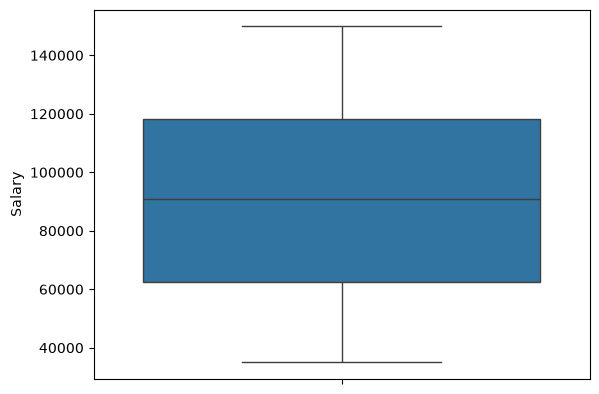

In [58]:
sns.boxplot(emp['Salary'])

In [63]:
# Q1=25%
# Q2=59%
# Q3=75%
# Q4=100%
# IQR=Q3-Q1
#    =120000-60000
#    =60000
# Outlier min < 1.5(IQR)
# Outlier max > 1.5(IQR)

In [64]:
#Finding Outliers
Q1_Salary= emp['Salary'].quantile(0.25)
Q2_Salary= emp['Salary'].quantile(0.5)
Q3_Salary= emp['Salary'].quantile(0.75)
IQR_Salary= Q3_Salary - Q1_Salary

In [65]:
outlier_salary = emp[
    ((emp['Salary']) < Q1_Salary - (1.5 * IQR_Salary))    |
    ((emp['Salary']) > Q3_Salary + (1.5 * IQR_Salary))
    ]

<Axes: ylabel='Bonus %'>

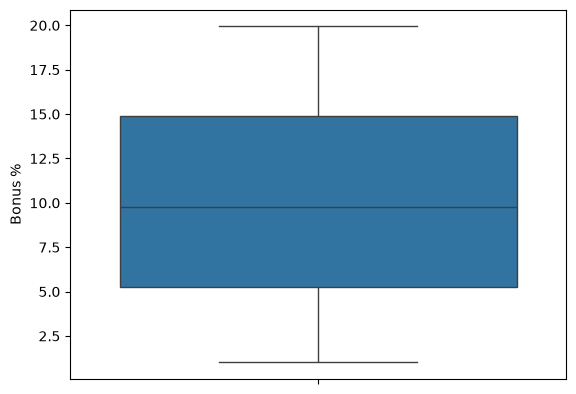

In [59]:
sns.boxplot(emp['Bonus %'])

<Axes: xlabel='Salary', ylabel='Team'>

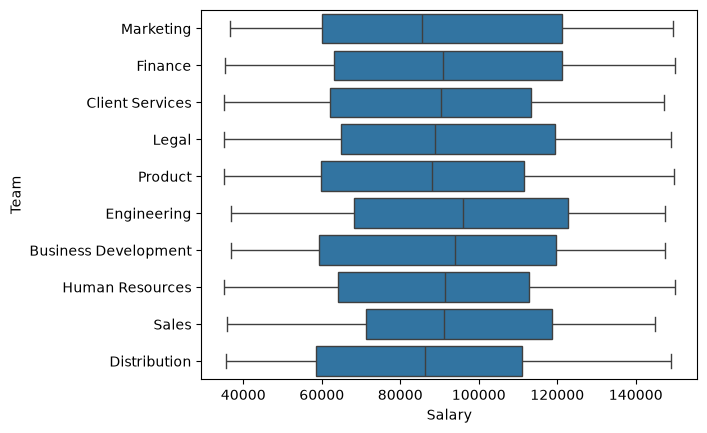

In [60]:
sns.boxplot(x='Salary',y='Team',data=emp)

<Axes: xlabel='Salary', ylabel='Team'>

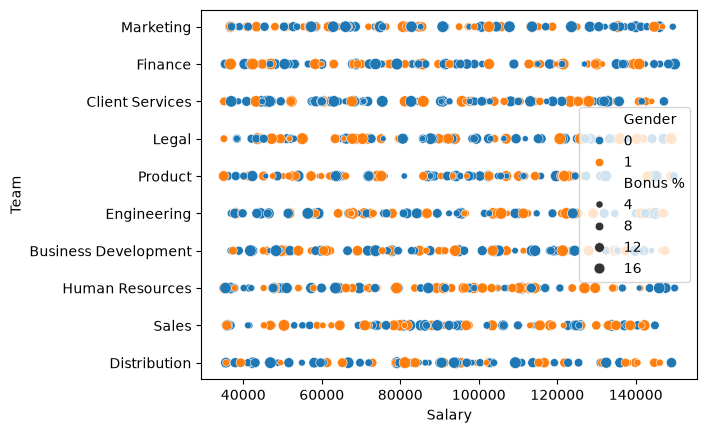

In [61]:
sns.scatterplot(x='Salary', y='Team', data=emp,hue='Gender',size='Bonus %')

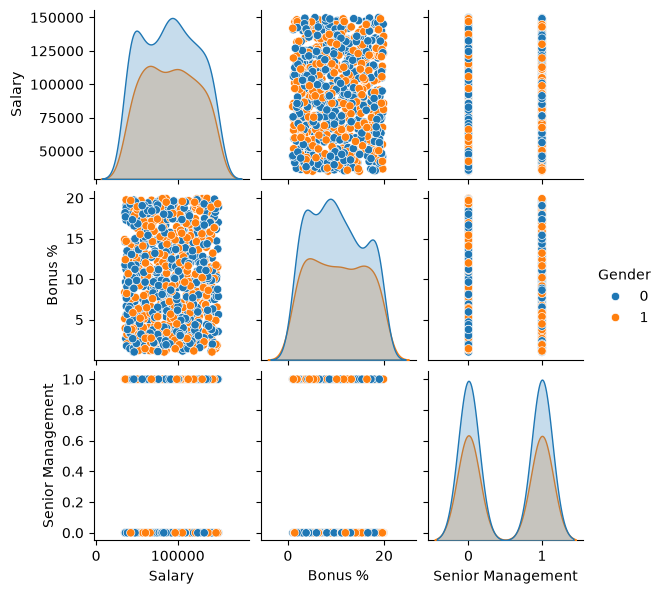

In [62]:
sns.pairplot(emp, hue='Gender',height=2)

In [88]:
# Load the Iris Dataset
iris= pd.read_csv("Iris.csv")
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [89]:
iris.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

<Axes: xlabel='SepalLengthCm'>

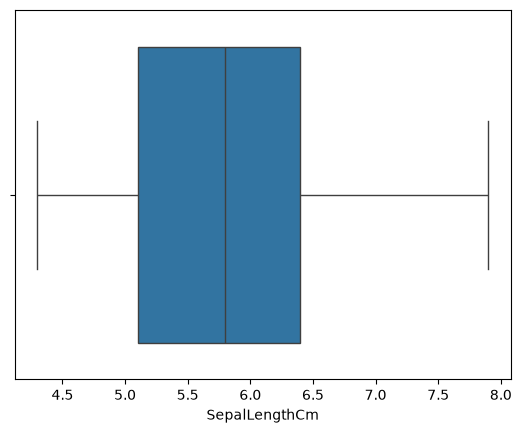

In [90]:
sns.boxplot(x='SepalLengthCm',data=iris)

<Axes: xlabel='SepalWidthCm'>

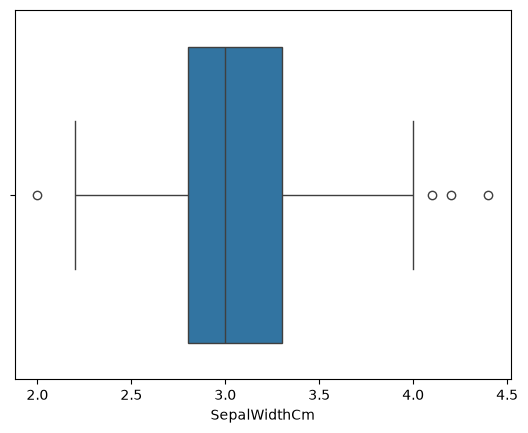

In [91]:
sns.boxplot(x='SepalWidthCm',data=iris)

In [92]:
Q1_sw = iris['SepalWidthCm'].quantile(0.25)
Q2_sw = iris['SepalWidthCm'].quantile(0.5)
Q3_sw = iris['SepalWidthCm'].quantile(0.75)
IQR_sw = Q3_sw - Q1_sw

In [93]:
outlier_sw = iris[
    ((iris['SepalWidthCm']) < Q1_sw - (1.5 * IQR_sw))    |
    ((iris['SepalWidthCm']) > Q3_sw + (1.5 * IQR_sw))
    ]

In [94]:
outlier_sw.shape

(4, 6)

In [103]:
lower = np.where(iris['SepalWidthCm'] < (Q1_sw - (1.5 * IQR_sw)))
upper = np.where(iris['SepalWidthCm'] > (Q1_sw + (1.5 * IQR_sw)))

In [100]:
iris.drop(lower[0],inplace=True)
iris.drop(upper[0],inplace=True)

In [101]:
iris.shape

(131, 6)

<Axes: xlabel='SepalWidthCm'>

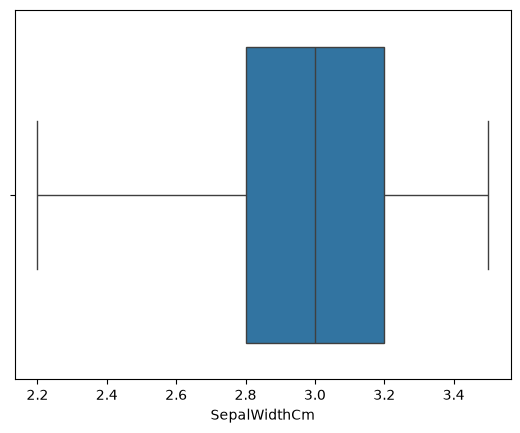

In [102]:
sns.boxplot(x='SepalWidthCm',data=iris)